### Pré-processamentos dos dados

Este notebook aplica filtros temporais e realiza a comparação da visualização dados antes e depois da aplicação dos filtros.

In [2]:
import mne
import numpy as np
import matplotlib.pyplot as plt

# Carregando os dados do arquivo .fif de epochs
epochs = mne.read_epochs('eldBETA_s01-epo.fif')
print("Alvos disponíveis:", list(epochs.event_id.keys()))

Reading c:\Users\Pichau\Desktop\topicosEspeciaisSistemas\eldBETA_s01-epo.fif ...
    Found the data of interest:
        t =       0.00 ...    6000.00 ms
        0 CTF compensation matrices available
Adding metadata with 3 columns
63 matching events found
No baseline correction applied
0 projection items activated
Alvos disponíveis: ['1', '2', '3', '4', '5', '6', '7', '8', '9']


In [4]:
def plots_evoked(evoked_data, channels_to_plot=None):
    '''
    Plota os dados evocados para cada canal.

    Parâmetros:
    evoked_data (mne.Evoked): Objeto contendo os dados evocados.
    '''
    
    data = evoked_data.get_data()[0]
    times = evoked_data.times
    ch_names = evoked_data.ch_names

    if channels_to_plot:
        idx = [ch_names.index(ch) for ch in channels_to_plot if ch in ch_names]
        data = data[idx]
        ch_names = [ch_names[i] for i in idx]
    
    n_channels = len(ch_names)
    ncols = 2
    nrows = int(np.ceil(n_channels / ncols))
    
    fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(12, 2.5 * nrows), sharex=True)
    axes = axes.flatten()

    for i, channel_name in enumerate(ch_names):
        ax = axes[i]

        ax.plot(times, data[i], label=channel_name, color="red")
        ax.set_title(f"Canal: {channel_name}")
        ax.grid(True, linestyle="--", alpha=0.5)

        # Rótulo do eixo Y apenas na coluna da esquerda
        if i % 2 == 0:
            ax.set_ylabel("Amplitude")

        # Rótulo do eixo X apenas na última linha
        if i >= (nrows * ncols) - 2:
            ax.set_xlabel("Tempo (s)")
            
    # Remove eixos vazios (caso o número de canais seja ímpar)
    for j in range(n_channels, len(axes)):
        fig.delaxes(axes[j])

    # Ajusta o layout para evitar sobreposições
    plt.tight_layout()
    plt.suptitle("Único Evento - Canais Isolados", y=1.02, fontsize=14)
    plt.show()

In [6]:
# dinamizando parâmetros

target = '8'
epo = 0

canais_alvo = ['O1', 'Oz', 'O2', 'PO3', 'PO4', 'POz', 'P3', 'Pz', 'P4']

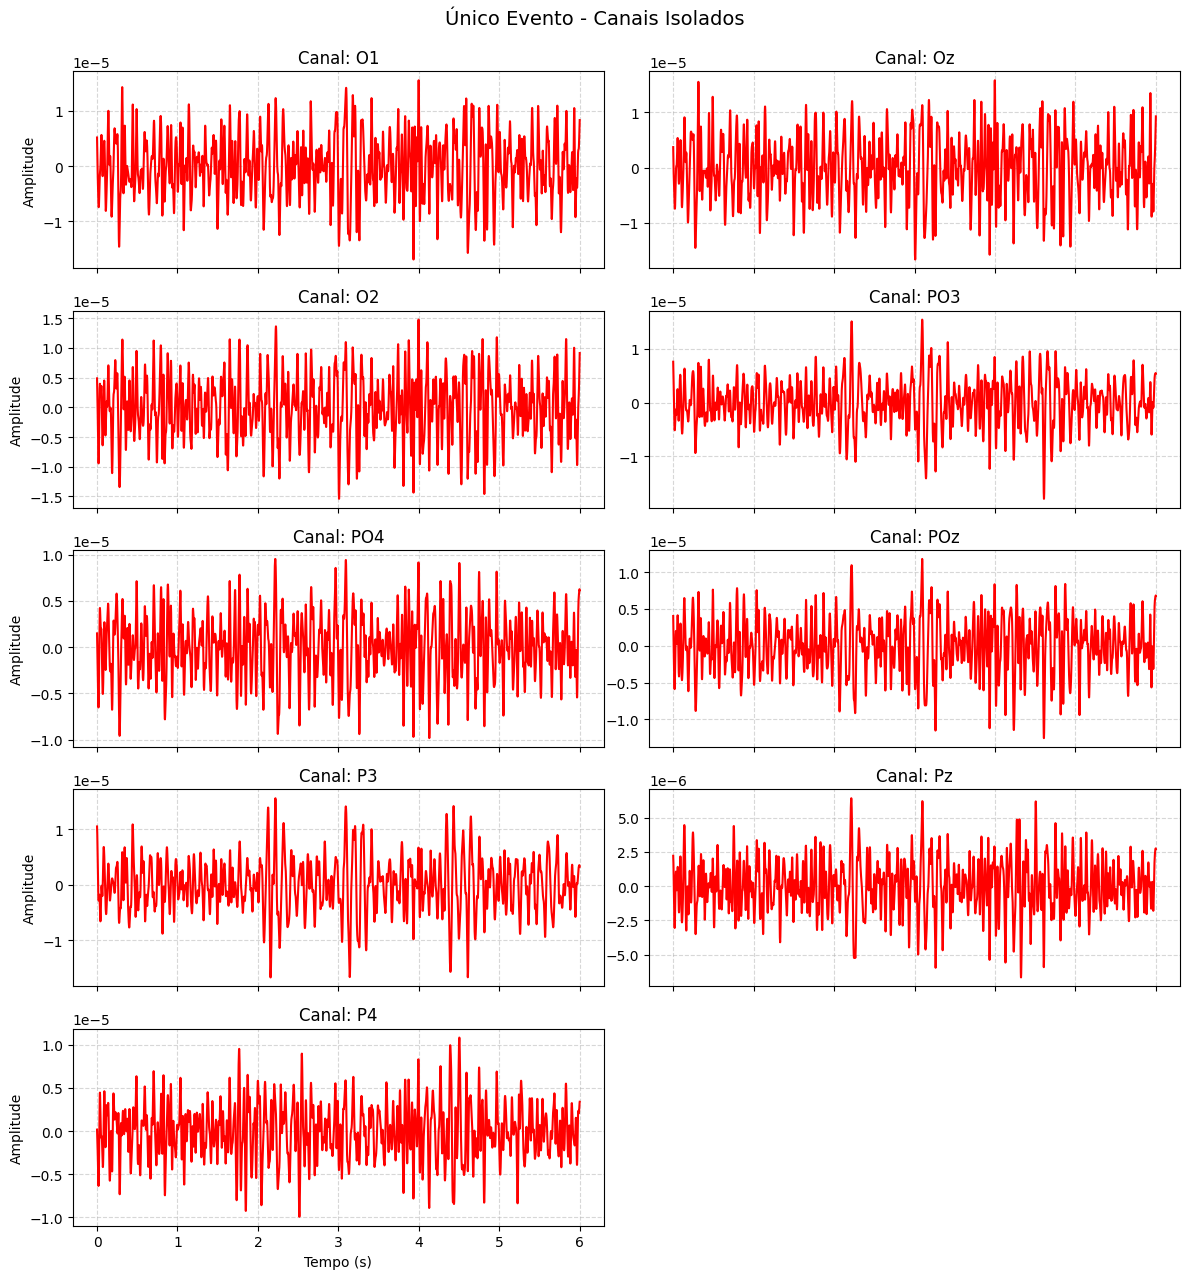

In [7]:
# obtendo 1 'hit' para o plot
plots_evoked(epochs[target][epo], channels_to_plot=canais_alvo)

Como os dados obtidos já estão pré-filtrados (0.1 - 30 Hz _bandpass_, 50 Hz _notch_), será demonstrado algumas aplicações de filtros somente como exemplos de aplicação.

Setting up band-pass filter from 6 - 40 Hz

IIR filter parameters
---------------------
Butterworth bandpass zero-phase (two-pass forward and reverse) non-causal filter:
- Filter order 16 (effective, after forward-backward)
- Cutoffs at 6.00, 40.00 Hz: -6.02, -6.02 dB



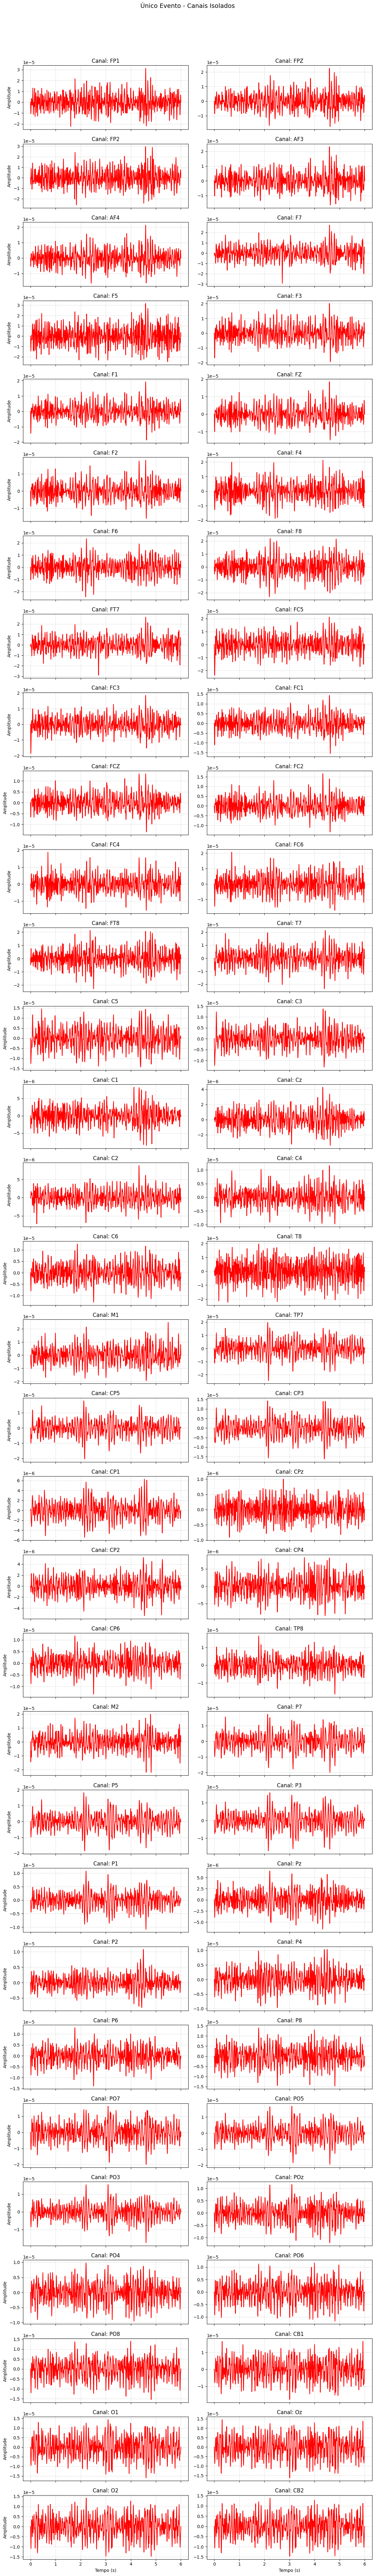

In [8]:
# dados modificados para máxima e mínima frequência para encontrar a faixa de dados úteis
low_freq = 6.0
high_freq = 40.0

epochs_filtradas = epochs.copy().filter(l_freq=low_freq, h_freq=high_freq, method='iir')
# epochs_filtradas = epochs.copy()
plots_evoked(epochs_filtradas[target][epo])

In [9]:
# salvando o objeto EpochsArray filtrado em um arquivo .fif
epochs_filtradas.save('eldBETA_s01_epo_filtrado.fif', overwrite=True)

C:\Users\Pichau\AppData\Local\Temp\ipykernel_2908\1492045000.py:2: RuntimeWarning: This filename (eldBETA_s01_epo_filtrado.fif) does not conform to MNE naming conventions. All epochs files should end with -epo.fif, -epo.fif.gz, _epo.fif or _epo.fif.gz
  epochs_filtradas.save('eldBETA_s01_epo_filtrado.fif', overwrite=True)


[WindowsPath('c:/Users/Pichau/Desktop/topicosEspeciaisSistemas/eldBETA_s01_epo_filtrado.fif')]